# Генерация текста с RNN и LSTM

Сравнение рекуррентных языковых моделей, BPE и unigram-токенизации, температуры генерации. Оценка perplexity и сходства текстов в пространстве LSA.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** Это отчётный ноутбук с сохранёнными результатами. Для полного воспроизведения дополнительно нужны dataset.py, model.py, train.py и исходный текстовый корпус; этих файлов среди вложений нет. Они не восстановлены и не заменены чужими реализациями.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


# Глубинное обучение, ИИ/МОЦП ВШЭ

## Домашнее задание 3. RNN.

### Общая информация

### Оценивание и штрафы

Максимально допустимая оценка за работу без бонусов — 10 баллов. Сдавать задание после указанного срока жесткого дедлайна нельзя.

Сдача работы после мягкого дедлайна штрафуется ступенчато, -1 балл в сутки. Один раз за модуль студентам предоставляется возможность использовать отсрочку и сдать в жесткий дедлайн без штрафа.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Использование генеративных моделей допустимо на следующих условиях:

- Количество кода, написанное генеративными моделями, не превышает 30%
- Указана модель, использованная для генерации, а также промпт
- В конце работы необходимо описать свой опыт использования генеративного ИИ для решения данного домашнего задания. Укажите как часто Вам приходилось исправлять код своими руками или просить модель что-то исправить. Было ли это быстрее, чем написать код самим?

В случае невыполнения этих требований работа не оценивается и оценка за неё не превышает 0 баллов.

### О задании

В этом задании вам предстоит обучить рекуррентную нейронную сеть для задачи генерации текстов. В качестве данных возьмем набор из 120 тысяч анекдотов (всех категорий от А до Я включительно). Его вы можете найти в файле `jokes.txt`, который доступен по ссылке https://www.dropbox.com/scl/fi/z1ihoqwdj3zxil28ha86i/jokes.txt?rlkey=66y4gpclxmzimc86aa6agnjn8&st=mff21u6h&dl=0 .

**коммент**

из-за совместимости заменила прошлую ячейку с autoreload на вот эту ниже и перенесла туда импорт из ячейки ниже

In [ ]:
import importlib
import dataset
import model
import train

importlib.reload(dataset)
importlib.reload(model)
importlib.reload(train)

from dataset import TextDataset
from model import LanguageModel
from train import training_epoch, validation_epoch, train

## Задание 1: Dataset (1 балл)

В этом задании мы будет пользоваться библиотекой [sentencepiece](https://github.com/google/sentencepiece), которая поддерживает разные форматы токенизации текстов, в том числе BPE, который мы и будем использовать. Реализуйте недостающие фрагменты кода в классе `TextDataset` в файле `dataset.py`. Датасет обучает sentencepiece токенизатор, токенизирует тексты, превращает токены в индексы и паддит до одной и той же длины (параметр `max_length`). Не забудьте, что для генерации текстов нам будут нужны специальные токены начала и конца последовательности, соответственно `BOS` и `EOS`. Существуют еще два специальных токена &mdash; паддинг `PAD` и токен `UNK`, заменяющий out-of-vocabulary токены.

In [ ]:
!pip install sentencepiece

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader

from tqdm.auto import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from transformers import AutoModelForCausalLM, AutoTokenizer

In [ ]:
train_set = TextDataset(data_file="jokes.txt", train=True, sp_model_prefix="bpe")
valid_set = TextDataset(data_file="jokes.txt", train=False, sp_model_prefix="bpe")

In [ ]:
# Код должен проходить тесты
assert len(train_set) + len(valid_set) == 120759

for _ in range(5):
    for dataset in (train_set, valid_set):
        indices, length = dataset[np.random.randint(len(dataset))]
        assert indices.shape == (dataset.max_length,)
        assert indices[0].item() == dataset.bos_id
        assert (indices == dataset.eos_id).sum().item() == 1

        eos_pos = indices.tolist().index(dataset.eos_id)
        assert torch.all(indices[eos_pos + 1 :] == dataset.pad_id)
        assert (indices != dataset.pad_id).sum() == length

**Итого**
- в `TextDataset` сначала текст переводится в индексы, а потом все последовательности приводятся к общей длине
- мы фиксируемся train/validation split, добавляются `BOS` и `EOS`, а короткие примеры дополняем `PAD`
- для запуска из чистой среды был явно задан `pad_id` при обучении SentencePiece в `dataset.py`, так как иначе `pad_id` оказывался равным `-1`, что ломало `Embedding` на GPU


## Задание 2 Language model (2 балла)

Реализуйте класс `LanguageModel` из файла `model.py`. Мы будем генерировать текст с помощью языковой модели &mdash; это авторегрессионная вероятностная модель, которая предсказывает распределение следующего токена при условии предыдущих:

$$
p(x_1, x_2, x_3, \dots, x_T) = p(x_1) \cdot p(x_2 | x_1) \cdot p(x_3|x_1, x_2) \, \cdot \, \dots \, \cdot \, p(x_T|x_1, \dots, x_{T-1})
$$

Мы будем реализовывать ее с помощью рекуррентной нейронной сети. Ваш код должен поддерживать возможность работать как с оригинальной [RNN](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html#torch.nn.RNN), так и c [LSTM](https://bitly.com/98K8eH). На каждом временном шаге модель возвращает логиты вероятностей для следующего токена. Модель будет работать в двух режимах (не путать с `.train()` и `.eval()`):

- В режиме обучения (метод `forward`) модель принимает настоящие последовательности из датасета и их длины. На каждом временном шаге возвращаются логиты вероятностей следующего токена, что позволяет считать лосс, обучаться на трейне и валидироваться на валидации.

- В режиме генерации (инференса, метод `inference`) модель принимает некоторый префикс (возможно пустой), с которого начинать генерацию, и продолжает его. Для этого на каждом шаге генерируются новые логиты, семплируется новый токен (из распределения, заданного логитами), и процесс продолжается, пока не будет сгенерирован токен `EOS` или не будет достигнуто ограничение на длину последовательности. **Обратите внимание**, что вам не нужно прогонять всю последовательность заново через RNN после каждого нового токена, это приведет к квадратичной сложности по длине последовательности. Вам достаточно обновлять скрытое состояние, подавая на вход новый сгенерированный токен и предыдущее скрытое состояние. Кроме того, чтобы получить больше контроля над генерацией, вводится параметр температуры `temp`. Перед семплированием нужно разделить на него логиты, полученные моделью.

In [ ]:
model = LanguageModel(train_set)

In [ ]:
# Код должен проходить тесты
for bs in [1, 4, 16, 64, 256]:
    indices = torch.randint(high=train_set.vocab_size, size=(bs, train_set.max_length))
    lengths = torch.randint(low=1, high=train_set.max_length + 1, size=(bs,))
    logits = model(indices, lengths)
    assert logits.shape == (bs, lengths.max(), train_set.vocab_size)

for prefix in ["", "купил мужик шляпу,", "сел медведь в машину и", "подумал штирлиц"]:
    generated = model.inference(prefix, temp=np.random.uniform(0.1, 10))
    assert type(generated) == str
    assert generated.startswith(prefix)

**Итого**
- эмбеддинги подаются в рекуррентный слой, затем скрытые состояния переводятся в логиты по словарю
- В `inference` используется авторегрессионная генерация по одному токену, чтобы скрытое состояние обновлялось последовательно, а не пересчитывалась вся строка заново


## Задание 3: Training (1.5 балла)

Всё, что нам осталось &mdash; реализовать цикл обучения. Заполните пропуски в файле `train.py`. Не забудьте, что мы учим модель предсказывать вероятность следующего, а не текущего токена. Также рекомендуется обрезать батч индексов по самой длинной последовательности, чтобы не гонять паддинги вхолостую. Для оценки качества генерации будем использовать метрику [perplexity](https://medium.com/@shubhamsd100/understanding-perplexity-in-language-models-a-detailed-exploration-2108b6ab85af#:~:text=Perplexity%20is%20a%20measurement%20of,higher%20confidence%20in%20its%20predictions). Реализуйте ее подсчет в функции `plot_losses` (да, для этого достаточно только значения лосса).

Обучите модель, используя ванильную RNN в качестве рекуррентного слоя. Сохраните чекпойнт обученной модели, он нам еще пригодится.

In [ ]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(dev)

cuda


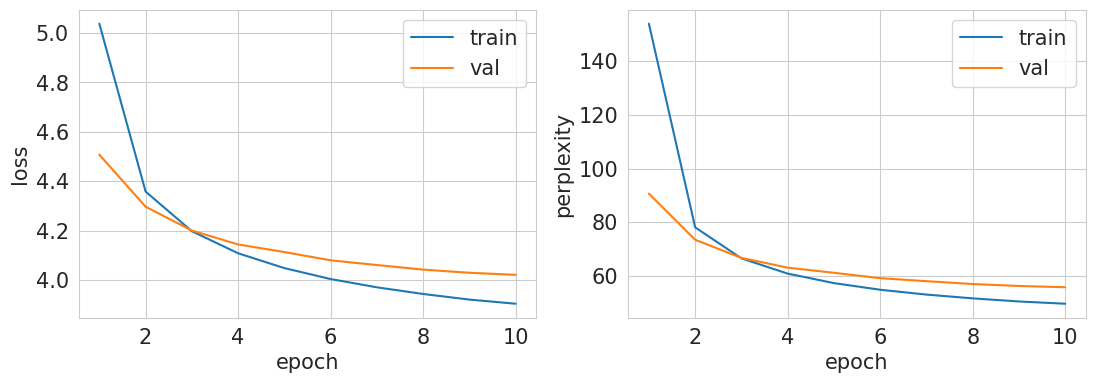

Generation examples:
в дотуда настроения в закашю, никто не нашла.
- вы, почему вы постоянно бой раз в сколдельщик, сынок, твоему своему другую часть?- встречаясь.
муж, корабля стрелка не хватает его, однако. теперь знаю - огромные днилизольных...
ветера- это правду, красивых, без брак отпузе.
в новостязе на разузерной голома, по- кораб.потец- ты чему вы уже подвигаю котлеты?- сладкого...
все сохранено в rnn_checkpoint.pt


In [ ]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

batch_size = 128
num_epochs = 10
learning_rate = 1e-3

train_load = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_load = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

rnn = LanguageModel(
    train_set,
    embed_size=256,
    hidden_size=256,
    rnn_type=nn.RNN,
    rnn_layers=1,
).to(dev)

optimizer = torch.optim.Adam(rnn.parameters(), lr=learning_rate)

train(
    rnn,
    optimizer,
    scheduler=None,
    train_loader=train_load,
    val_loader=val_load,
    num_epochs=num_epochs
)

torch.save(
    {
        'model_state_dict': rnn.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'model_kwargs': {
            'embed_size': 256,
            'hidden_size': 256,
            'rnn_type': 'RNN',
            'rnn_layers': 1,
        },
        'sp_model_prefix': 'bpe',
    },
    'rnn_checkpoint.pt')

print('все сохранено в rnn_checkpoint.pt')


**Итого**

- loss и perplexity на rnn снижаются, а значит цикл обучения реализован правильно
- по примерам генерации видно, что модель выучивает общий стиль корпуса, но при этом текст получается несвязный, что ожидаемо для простой RNN на такой задаче
- мы используем `DataLoader`, `Adam`, сдвиг входа и таргета на один токен и сохраняем чекпойнт


## Задание 4: LSTM (0.5 балла)

Обучите аналогичную модель, но с LSTM в качестве рекуррентного слоя. Сравните модели по метрикам и генерации. Не забывайте про чекпойнты!

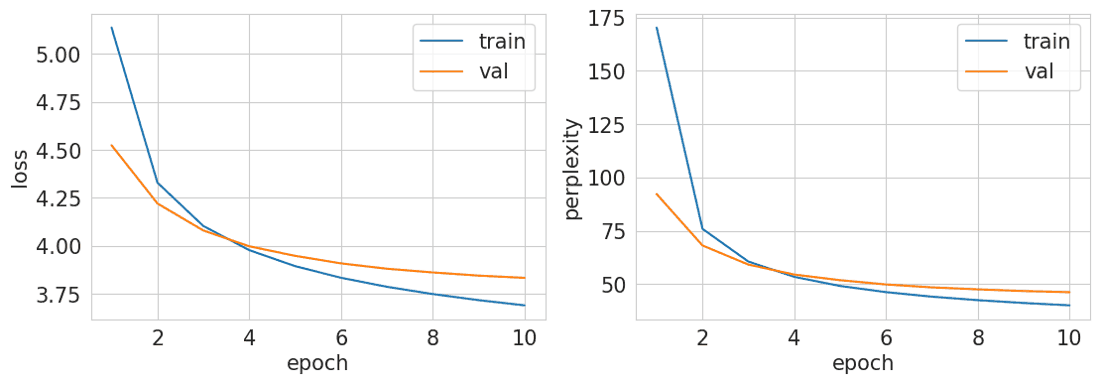

Generation examples:
- парово выходят как сделать!- а так попадают, дорогой, а ты болезнью и ежик, коллелез в школах!
- помните, никода дали жене таператуанка, они даже да не слушают вибра.- почему?- вот сейчас пойжете кориу, владимирское из лошадь.
- бибиатл. от чего, пора тебе директору массона?- да я здесь уже двадцать.
- квали, и лежишь в три раза не горен кислород. наконец ждет ребенок.- мама, смотри какая у тебя гады нет.- и побы, я надея работать, и я спрашиваю, а лето! мы как меня слушались?
у нас врывается, который хотел бы речь, как из-за того, что хлопают его, чтобы днем нет.
все сохранено в lstm_checkpoint.pt


In [ ]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

lstm = LanguageModel(
    train_set,
    embed_size=256,
    hidden_size=256,
    rnn_type=nn.LSTM,
    rnn_layers=1,
).to(dev)

optimizer = torch.optim.Adam(lstm.parameters(), lr=learning_rate)

train(
    lstm,
    optimizer,
    scheduler=None,
    train_loader=train_load,
    val_loader=val_load,
    num_epochs=num_epochs
)

torch.save(
    {
        'model_state_dict': lstm.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'model_kwargs': {
            'embed_size': 256,
            'hidden_size': 256,
            'rnn_type': 'LSTM',
            'rnn_layers': 1,
        },
        'sp_model_prefix': 'bpe',
    },
    'lstm_checkpoint.pt'
)
print('все сохранено в lstm_checkpoint.pt')

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=val_load.dataset.pad_id)

rnn_val_loss = validation_epoch(rnn, criterion, val_load, tqdm_desc='RNN val')
lstm_val_loss = validation_epoch(lstm, criterion, val_load, tqdm_desc='LSTM val')

print('\nСравнение по метрикам:')
print(f'RNN  val loss: {rnn_val_loss:.4f}, perplexity: {math.exp(rnn_val_loss):.4f}')
print(f'LSTM val loss: {lstm_val_loss:.4f}, perplexity: {math.exp(lstm_val_loss):.4f}')

print('\nСравнение генерации:')
for i in range(3):
    print(f'\nПример {i + 1}')
    print('RNN :', rnn.inference())
    print('LSTM:', lstm.inference())

RNN val:   0%|          | 0/48 [00:00<?, ?it/s]

LSTM val:   0%|          | 0/48 [00:00<?, ?it/s]


Сравнение по метрикам:
RNN  val loss: 4.0207, perplexity: 55.7427
LSTM val loss: 3.8336, perplexity: 46.2294

Сравнение генерации:

Пример 1
RNN : на дверях звание футбола разглам извечной глупостиром.
LSTM: - подруга встречалась- знала, можно поработать...- и, не ты, врачающие сиськи.- а от нашей комиссией? больше жены капустники живут людей.

Пример 2
RNN : - мама, я хочу ночью читать газету, ряка дура на скрилила и вилла тысяч, негодная?- он херня, я туда звонцу успехота, в аптекву сзади не голые даже мужчины всегда не подсудимый...
LSTM: - плохой, парень с ним следить мне папа.наковая волну на рыбалку, а ушел. лучше загорается в челюсть...

Пример 3
RNN : в сша замосковшаяся жена решает сыр.
LSTM: - аватая дезерты, дайте мне скучно!- хорошая.- а какая егнация?- гуляют.


**Итого**

- на основе метрик LSTM лучше RNN: `val loss` ниже (`3.83` и `4.02`), `perplexity` ниже (`46.23` против `55.74`)
- Генерация у LSTM все еще шумная, но в среднем выглядит чуть устойчивее и не такая хаотичная, как у RNN
- так как LSTM на данном этапе лучше, мы выберем LSTM как лучший рекуррентный слоя для работы над проектом дальше

## Задание 5: Sampling temperature (0.5 балла)

Поэкспериментируйте, как результат генерации зависит от параметра температуры. Попробуйте генерацию с разными префиксами. Сделайте выводы.

In [ ]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

temperatures = [0.3, 0.7, 1.0, 1.5]
prefixes = ['', 'Приходят в бар', 'Штирлиц', 'Американец', 'Вовочка']

model_for_generation = lstm

for p in prefixes:
    print('=' * 80)
    print(f'Префикс: {p!r}')
    for temp in temperatures:
        print(f'temp={temp}: {model_for_generation.inference(prefix=p, temp=temp)}')


Префикс: ''
temp=0.3: - как вы, что вы не хотите, чтобы выйти из дома?- нет, я не понимаю, что ты не хочешь, чтобы ты не знаешь, что ты не знаешь, что ты мне сделал, что он не пробовал?
temp=0.7: - доча, выл видите, пожалуйста, в котором что-то проводила в мою комнату. а ты даешь.- ну хорошо, конечно, помыли.
temp=1.0: - скажи злее глухие, чучело же от жизни не было.- а ты сидел в баре?- кистюрически карьер!
temp=1.5: совет приговорью, запомните настоящие - потому тянемемэлобор. девушка никогдаю три эта пудовским, похож - я закон взитзнавать...надцать его не нравится нашлу это делать. уже до дощудал до того без фильтно голосуют пят гибель от пустудский бабуками?!... даже ритому потородется картовика ссмотреть глаз? мне какой год?.
Префикс: 'Приходят в бар'
temp=0.3: Приходят в барприходят в бардачке, что в россии не приходилось в штанах.
temp=0.7: Приходят в барприходят в барле, голосова, которая его знает, что роль - непонятная, зависит от мамы.
temp=1.0: Приходят в барприходят в барр

**Итого**

- При низкой температуре (`0.3`) генерация становится более предсказуемой и повторяющейся
- При температуре около `0.7-1.0` тексты выглядят наиболее сбалансированными: в них больше разнообразия, но они еще не полностью распадаются
- При высокой температуре (`1.5`) текст становится более случайным и хуже держит структуру
- Повтор первого слова в префиксе связан с текущей реализацией `inference`: префикс вручную добавляется к результату, а модель часто еще раз генерирует то же слово как первое продолжение


## Задание 5: Tokenizers (1 балл)

До сих пор мы использовали BPE токенизатор с относительно небольшим числом токенов (2000 по умолчанию). Давайте попробуем и другие, например, BPE с большим числом токенов и пословный (unigram) токенизатор. Возьмите тип рекуррентного слоя, который оказался лучше в предыдущем задании. Обучите модели на таких токенизаторах и сравните их генерацию. Не забывайте сохранять чекпойнты. Правильно ли сравнивать между собой получившиеся модели по значению perplexity? Почему?

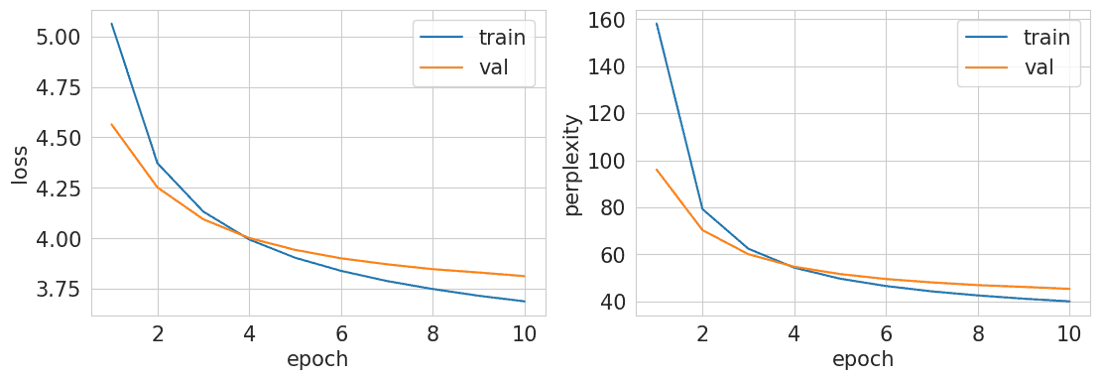

Generation examples:
ученые беременное злое и средство страны играют в трусы, вон ответили миллиар простысь.
- а кто очень был пьян настолько серьезный, что гина каждый вечер на него бегают возле жены?- 2 ⁇  способам учатся десятонцать за тысячи тело.
- девушка, он бежит предотворование, и пойдем ем, ушел в гля и зарегд с нынешкой- понрависьте его.- по-то мою табагурсизером наша четыре. меня больше, чем твои похороны со стороны 2це и в минуту хорошими блины!
- как наша жизнь у тебя в сказку делам. врач!выпала на и со слоном.- я же вижу, когда бог детей шну!
после нее взяла в обманову 50 тысяч дед новичй себя внеска ⁇  рух, а не всегда ртом.
bpe_2000
prefix='': стоянки, как масло - это когда нашли в такое возможность женское так просто.
prefix='Приходят в бар': Приходят в барприходят в бар.- понемагу?- исполнилось, я бы уже не хочу романтичный магазин, а ты мне немного не можешь!
prefix='Штирлиц': Штирлицштирлиц вышел в  ⁇  союза протеста. за что вы прочитал, что просроченный коричш.- м

In [ ]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

def fit_and_save_model(train_set, valid_set, model_name, model_type='bpe', vocab_size=2000,
                       rnn_type=nn.LSTM, num_epochs=10, batch_size=128, learning_rate=1e-3):
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)

    model = LanguageModel(
        train_set,
        embed_size=256,
        hidden_size=256,
        rnn_type=rnn_type,
        rnn_layers=1,
    ).to(dev)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train(model, optimizer, scheduler=None,
          train_loader=train_loader, val_loader=val_loader, num_epochs=num_epochs)

    rnn_name = 'LSTM' if rnn_type == nn.LSTM else 'RNN'
    ckpt_path = f'{model_name}_checkpoint.pt'

    torch.save(
        {
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'model_kwargs': {
                'embed_size': 256,
                'hidden_size': 256,
                'rnn_type': rnn_name,
                'rnn_layers': 1,
            },
            'sp_model_prefix': model_name,
            'vocab_size': vocab_size,
            'model_type': model_type,
        },
        ckpt_path
    )
    return model, ckpt_path


bpe_big_train = TextDataset('jokes.txt', train=True, sp_model_prefix='bpe_big', vocab_size=4000, model_type='bpe')
bpe_big_valid = TextDataset('jokes.txt', train=False, sp_model_prefix='bpe_big', vocab_size=4000, model_type='bpe')

unigram_train = TextDataset('jokes.txt', train=True, sp_model_prefix='unigram', vocab_size=2000, model_type='unigram')
unigram_valid = TextDataset('jokes.txt', train=False, sp_model_prefix='unigram', vocab_size=2000, model_type='unigram')

bpe_small_model = lstm
bpe_big_model, _ = fit_and_save_model(bpe_big_train, bpe_big_valid, 'bpe_big', model_type='bpe', vocab_size=4000)
unigram_model, _ = fit_and_save_model(unigram_train, unigram_valid, 'unigram', model_type='unigram', vocab_size=2000)

models_by_tokenizer = {
    'bpe_2000': bpe_small_model,
    'bpe_4000': bpe_big_model,
    'unigram_2000': unigram_model,
}


for name, model in models_by_tokenizer.items():
    print('=' * 80)
    print(name)
    for p in prefixes:
        print(f'prefix={p!r}: {model.inference(prefix=p)}')

**Итого**

- мы сравниваем три токенизатора на одной и той же архитектуре LSTM
- лучше всего результаты у `bpe_2000`, а `bpe_4000` и `unigram_2000` дают более шумную генерацию
- perplexity между моделями с разными токенизаторами сравнивать напрямую некорректно, потому что тексты разбиваются на разные токены и loss считается в разном пространстве токенов

## Задание 6. Latent Semantic Analysis (2 балла)

Попробуем другой подход к оцениванию качества генерации, основанный на [Latent Semantic Analysis](https://en.wikipedia.org/wiki/Latent_semantic_analysis). Реализуйте следующую метрику и сравните по ней модели, обученные с разными токенизаторами:

1. Генерируем обученной моделью выборку текстов, совпадающую по размеру с валидационной выборкой.
2. Объединяем две выборки текстов (валидационную и сгенерированную) в один корпус. Обратите внимание, что наша токенизация в общем случае необратима, поэтому для чистоты эксперимента нужно закодировать и декодировать валидационную выборку.
3. Генерируем tf-idf матрицу для полученного корпуса.
4. Понижаем размерность матрицы с помощью [SVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html).
5. Теперь у нас есть векторы, описывающие валидационные и сгенерированные тексты, лежащие в одном пространстве. Для каждого вектора, отвечающего сгенерированному тексту, найдем наибольший cosine similarity между ним и вектором валидационного текста. Усредним такие similarity по всем сгенерированным текстам и получим число, характеризующее похожесть сгенерированной выборки на валидационную.

Какие плюсы и минусы есть у описанной метрики?

In [17]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

val_by_tokenizer = {
    'bpe_2000': valid_set,
    'bpe_4000': bpe_big_valid,
    'unigram_2000': unigram_valid,
}

def decode_validation_texts(dataset):
    return dataset.ids2text(dataset.text2ids(dataset.texts))

def generate_texts(model, n_texts, prefix='', temp=1.0):
    texts = []
    for _ in tqdm(range(n_texts)):
        texts.append(model.inference(prefix=prefix, temp=temp))
    return texts


def lsa_similarity_score(valid_texts, generated_texts, n_components=128):
    corpus = list(valid_texts) + list(generated_texts)

    vectorizer = TfidfVectorizer(min_df=2)
    tfidf = vectorizer.fit_transform(corpus)

    max_components = min(tfidf.shape[0] - 1, tfidf.shape[1] - 1)
    n_components = min(n_components, max_components)
    n_components = max(n_components, 1)

    svd = TruncatedSVD(n_components=n_components, random_state=42)
    vectors = svd.fit_transform(tfidf)

    n_valid = len(valid_texts)
    valid_vectors = vectors[:n_valid]
    generated_vectors = vectors[n_valid:]

    similarities = cosine_similarity(generated_vectors, valid_vectors)
    score = similarities.max(axis=1).mean()

    return score, valid_vectors, generated_vectors


lsa_results = {}
lsa_vectors = {}
generated_samples = {}

for name, model in models_by_tokenizer.items():
    print(f'Обрабатывается {name}...')

    dataset = val_by_tokenizer[name]
    valid_texts_decoded = decode_validation_texts(dataset)
    generated_texts = generate_texts(model, len(valid_texts_decoded))

    score, valid_vectors, generated_vectors = lsa_similarity_score(
        valid_texts_decoded,
        generated_texts
    )

    lsa_results[name] = score
    lsa_vectors[name] = (valid_vectors, generated_vectors)
    generated_samples[name] = generated_texts

print('\nLSA результаты:')
for name, score in lsa_results.items():
    print(f'{name}: {score:.4f}')


Обрабатывается bpe_2000...


  0%|          | 0/6037 [00:00<?, ?it/s]

Обрабатывается bpe_4000...


  0%|          | 0/6037 [00:00<?, ?it/s]

Обрабатывается unigram_2000...


  0%|          | 0/6037 [00:00<?, ?it/s]


LSA результаты:
bpe_2000: 0.6831
bpe_4000: 0.6856
unigram_2000: 0.6950


**Итого**

- по LSA лучший результат у `unigram_2000` (`0.6950`), затем у `bpe_4000` (`0.6856`), а самый низкий результат у `bpe_2000` (`0.6831`)
- то есть сгенерированные тексты `unigram_2000` в среднем ближе к валидационным в пространстве TF-IDF и SVD
- Метрика полезна как быстрое сравнение выборок на уровне лексико-семантической близости(плюс), но она не проверяет связность текста, грамматику и насколько смешной анекдот (минусы)


## Задание 7. Visualization (1 балл)

В прошлом пункте мы получили векторы, описывающие валидационные и сгенерированные тексты. Попробуем визуализировать их. Примените [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) к этим векторам и нарисуйте scatter-plot с получившимися двумерными представлениями. Точки, соответствующие валидационным и сгенерированным текстам, должны быть разного цвета. Визуализируйте таким образом все три модели для разных токенизаторов.

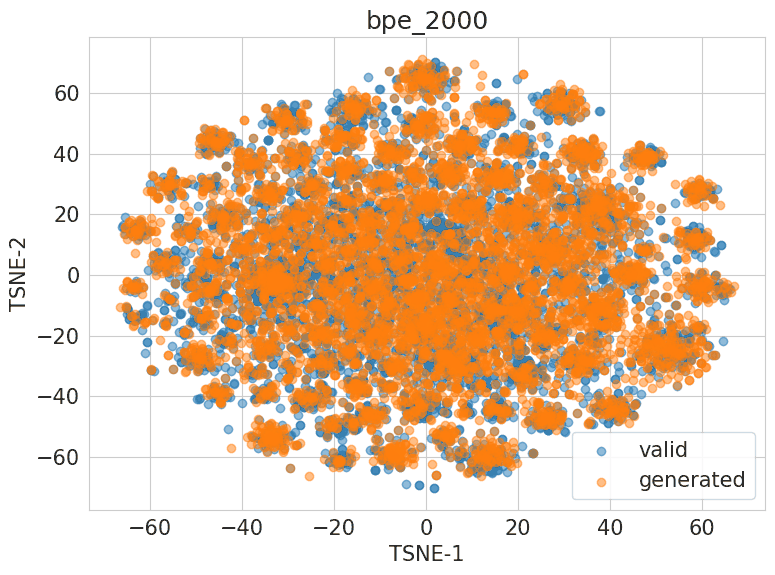

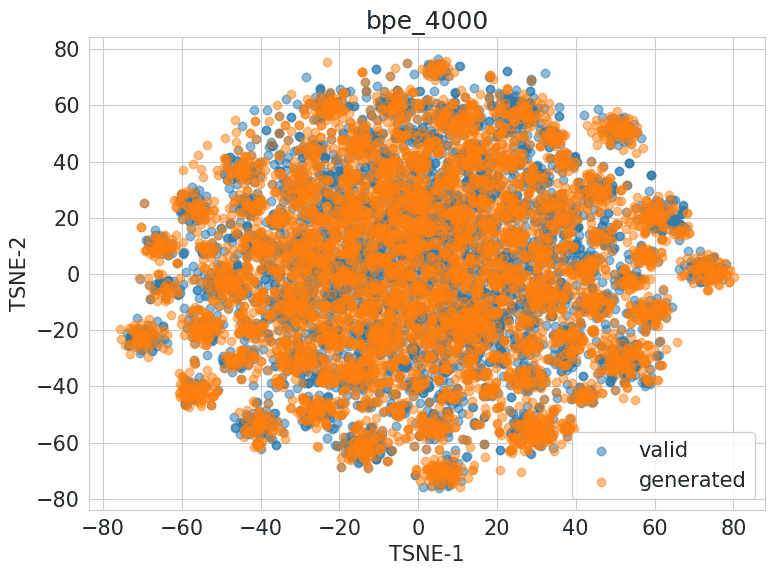

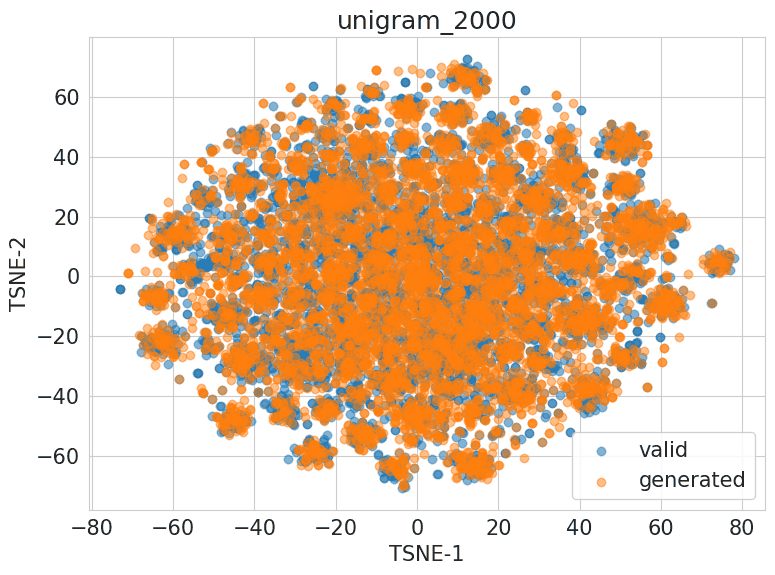

In [18]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

for name, (valid_vectors, generated_vectors) in lsa_vectors.items():
    vectors = np.vstack([valid_vectors, generated_vectors])
    labels = np.array(['valid'] * len(valid_vectors) + ['generated'] * len(generated_vectors))

    tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
    points = tsne.fit_transform(vectors)

    plt.figure(figsize=(8, 6))
    for label in ['valid', 'generated']:
        mask = labels == label
        plt.scatter(points[mask, 0], points[mask, 1], alpha=0.5, label=label)

    plt.title(name)
    plt.xlabel('TSNE-1')
    plt.ylabel('TSNE-2')
    plt.legend()
    plt.tight_layout()
    plt.show()

**Итого**

- для каждой модели мы построили двумерную проекция, где точки `valid` и `generated` показаны разными цветами
- чем сильнее перекрываются облака `generated` и `valid`, тем ближе распределение генерации к валидационной выборке, судя по графикам `unigram_2000` в большей степени соответствует этому, хотя визуализация довольна схожая во всех трех случаях, так как метрики не так сильно друг от друга отличаются


## Задание 8. ruGPT perplexity (2 балла)

Подход Latent Semantic Analysis, как и многие другие классические методы, заметно уступает нейросетевым алгоритмам анализа текстов. Вернемся к оцениванию качества генерации с помощью perplexity, для этого возьмем большую и хорошо обученную языковую модель, которая училась на огромном корпусе русских текстов. Считается, что большие языковые модели хорошо выучивают естественный язык, потому с их помощью мы сможем оценивать качество наших маленьких моделей для генерации анекдотов. Для этого мы воспользуемся сервисом [HuggingFace](https://huggingface.co/), который содержит огромное число обученных моделей для самых разных задач. Изучите и реализуйте, [подсчет perplexity](https://huggingface.co/docs/transformers/perplexity), с использованием обученной языковой модели. В качестве модели возьмите [ruGPT3-small](https://huggingface.co/sberbank-ai/rugpt3small_based_on_gpt2). Сгенерируйте синтетические выборки тремя моделями, обученными выше (можете взять выборки из задания 6), и сравните их по perplexity.

In [19]:
# YOUR CODE HERE (⊃｡•́‿•̀｡)⊃━✿✿✿✿✿✿

rugpt_name = 'sberbank-ai/rugpt3small_based_on_gpt2'
rugpt_tokenizer = AutoTokenizer.from_pretrained(rugpt_name)
rugpt_model = AutoModelForCausalLM.from_pretrained(rugpt_name).to(dev)
rugpt_model.eval()

def text_perplexity(text, model, tokenizer, stride=256):
    if len(text.strip()) == 0:
        return float('inf')

    encodings = tokenizer(text, return_tensors='pt', truncation=False)
    input_ids = encodings.input_ids.to(dev)

    seq_len = input_ids.size(1)
    max_length = model.config.n_positions

    nll_sum = 0.0
    n_tokens = 0
    prev_end_loc = 0

    for begin_loc in range(0, seq_len, stride):
        end_loc = min(begin_loc + max_length, seq_len)
        trg_len = end_loc - prev_end_loc

        input_ids_slice = input_ids[:, begin_loc:end_loc]
        target_ids = input_ids_slice.clone()
        target_ids[:, :-trg_len] = -100

        with torch.no_grad():
            outputs = model(input_ids_slice, labels=target_ids)
            neg_log_likelihood = outputs.loss * trg_len

        nll_sum += neg_log_likelihood.item()
        n_tokens += trg_len
        prev_end_loc = end_loc

        if end_loc == seq_len:
            break

    return math.exp(nll_sum / max(n_tokens, 1))


def dataset_perplexity(texts, model, tokenizer, max_texts=256):
    texts = [text for text in texts[:max_texts] if len(text.strip()) > 0]
    ppls = [text_perplexity(text, model, tokenizer) for text in tqdm(texts)]
    return sum(ppls) / len(ppls)


rugpt_results = {}
for name, texts in generated_samples.items():
    rugpt_results[name] = dataset_perplexity(
        texts,
        rugpt_model,
        rugpt_tokenizer,
        max_texts=256
    )

for name, ppl in rugpt_results.items():
    print(f'{name}: ruGPT perplexity = {ppl:.4f}')

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie transformer.wte.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
GPT2LMHeadModel LOAD REPORT from: sberbank-ai/rugpt3small_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 
transformer.h.{0...11}.attn.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/256 [00:00<?, ?it/s]

  0%|          | 0/256 [00:00<?, ?it/s]

  0%|          | 0/256 [00:00<?, ?it/s]

bpe_2000: ruGPT perplexity = 2961.9462
bpe_4000: ruGPT perplexity = 3346.4572
unigram_2000: ruGPT perplexity = 3426.6027


**Итого**

- По внешней оценке лучшей оказывается модель с `bpe_2000`, затем `bpe_4000` и последняя `unigram_2000`
- Здесь perplexity лучше, когда меньше, потому что ру-модель считает такие тексты более правдоподобными с точки зрения естественного языка
- Результат разнится с LSA: среди трех вариантов `bpe_2000` дает худший показатель, хотя в целом они не так сильно друг от друга отличаются
- Это различие можно объяснить тем, что LSA оценивает прежде всего лексико-семантическую близость сгенерированных текстов к валидационной выборке в пространстве TF-IDF и SVD, тогда как `ruGPT perplexity` оценивает тексты с точки зрения общей языковой правдоподобности, поэтому разные метрики подчеркивают разные стороны качества генерации


## Бонус (0.1 балл)

Покажите лучший анекдот, который удалось сгенерировать вашей модели. Если проверяющий найдет его смешным, то поставит 0.1 балла.